In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [42]:
import os

print(os.listdir())

['.git', '.gitignore', 'fifa21 raw data v2.csv', 'fifa21_analysis.ipynb', 'README.md', 'venv']


In [43]:
df = pd.read_csv("fifa21 raw data v2.csv")

print("FIFA 21 dataset loaded successfully!")

FIFA 21 dataset loaded successfully!


C:\Users\hp\AppData\Local\Temp\ipykernel_27508\1813123160.py:1: DtypeWarning: Columns (76: Hits) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("fifa21 raw data v2.csv")


In [44]:
df.head()

,ID,Name,LongName,photoUrl,playerUrl,Nationality,Age,↓OVA,POT,Club,...,A/W,D/W,IR,PAC,SHO,PAS,DRI,DEF,PHY,Hits
0,158023,L. Messi,Lionel Messi,https://cdn.sofifa.com/players/158/023/21_60.png,http://sofifa.com/player/158023/lionel-messi/2...,Argentina,33,93,93,\n\n\n\nFC Barcelona,...,Medium,Low,5 ★,85,92,91,95,38,65,771
1,20801,Cristiano Ronaldo,C. Ronaldo dos Santos Aveiro,https://cdn.sofifa.com/players/020/801/21_60.png,http://sofifa.com/player/20801/c-ronaldo-dos-s...,Portugal,35,92,92,\n\n\n\nJuventus,...,High,Low,5 ★,89,93,81,89,35,77,562
2,200389,J. Oblak,Jan Oblak,https://cdn.sofifa.com/players/200/389/21_60.png,http://sofifa.com/player/200389/jan-oblak/210006/,Slovenia,27,91,93,\n\n\n\nAtlético Madrid,...,Medium,Medium,3 ★,87,92,78,90,52,90,150
3,192985,K. De Bruyne,Kevin De Bruyne,https://cdn.sofifa.com/players/192/985/21_60.png,http://sofifa.com/player/192985/kevin-de-bruyn...,Belgium,29,91,91,\n\n\n\nManchester City,...,High,High,4 ★,76,86,93,88,64,78,207
4,190871,Neymar Jr,Neymar da Silva Santos Jr.,https://cdn.sofifa.com/players/190/871/21_60.png,http://sofifa.com/player/190871/neymar-da-silv...,Brazil,28,91,91,\n\n\n\nParis Saint-Germain,...,High,Medium,5 ★,91,85,86,94,36,59,595


In [45]:
df.shape

(18979, 77)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18979 entries, 0 to 18978
Data columns (total 77 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                18979 non-null  int64 
 1   Name              18979 non-null  str   
 2   LongName          18979 non-null  str   
 3   photoUrl          18979 non-null  str   
 4   playerUrl         18979 non-null  str   
 5   Nationality       18979 non-null  str   
 6   Age               18979 non-null  int64 
 7   ↓OVA              18979 non-null  int64 
 8   POT               18979 non-null  int64 
 9   Club              18979 non-null  str   
 10  Contract          18979 non-null  str   
 11  Positions         18979 non-null  str   
 12  Height            18979 non-null  str   
 13  Weight            18979 non-null  str   
 14  Preferred Foot    18979 non-null  str   
 15  BOV               18979 non-null  int64 
 16  Best Position     18979 non-null  str   
 17  Joined            18979

In [47]:
df.columns.tolist()

['ID',
 'Name',
 'LongName',
 'photoUrl',
 'playerUrl',
 'Nationality',
 'Age',
 '↓OVA',
 'POT',
 'Club',
 'Contract',
 'Positions',
 'Height',
 'Weight',
 'Preferred Foot',
 'BOV',
 'Best Position',
 'Joined',
 'Loan Date End',
 'Value',
 'Wage',
 'Release Clause',
 'Attacking',
 'Crossing',
 'Finishing',
 'Heading Accuracy',
 'Short Passing',
 'Volleys',
 'Skill',
 'Dribbling',
 'Curve',
 'FK Accuracy',
 'Long Passing',
 'Ball Control',
 'Movement',
 'Acceleration',
 'Sprint Speed',
 'Agility',
 'Reactions',
 'Balance',
 'Power',
 'Shot Power',
 'Jumping',
 'Stamina',
 'Strength',
 'Long Shots',
 'Mentality',
 'Aggression',
 'Interceptions',
 'Positioning',
 'Vision',
 'Penalties',
 'Composure',
 'Defending',
 'Marking',
 'Standing Tackle',
 'Sliding Tackle',
 'Goalkeeping',
 'GK Diving',
 'GK Handling',
 'GK Kicking',
 'GK Positioning',
 'GK Reflexes',
 'Total Stats',
 'Base Stats',
 'W/F',
 'SM',
 'A/W',
 'D/W',
 'IR',
 'PAC',
 'SHO',
 'PAS',
 'DRI',
 'DEF',
 'PHY',
 'Hits']

In [48]:
df_raw = df.copy()

print("Original dataset backup created!")

Original dataset backup created!


In [49]:
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

newline_columns = []

for col in text_columns:
    if df[col].astype("string").str.contains(
        r"[\r\n]", na=False
    ).any():
        newline_columns.append(col)

print("Columns containing newline characters:")
print(newline_columns)


Columns containing newline characters:
['Club']


In [50]:
for col in newline_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.replace(r"[\r\n]+", " ", regex=True)
        .str.strip()
    )

print("Newline characters removed successfully!")

Newline characters removed successfully!


In [51]:
df[["Name", "Club"]].head()

,Name,Club
0,L. Messi,FC Barcelona
1,Cristiano Ronaldo,Juventus
2,J. Oblak,Atlético Madrid
3,K. De Bruyne,Manchester City
4,Neymar Jr,Paris Saint-Germain


In [52]:
# examining the Height Value
print("HEIGHT VALUES:")
print(df["Height"].unique())


# Weight Values
print("WEIGHT VALUES:")
print(df["Weight"].unique())

HEIGHT VALUES:
<StringArray>
['170cm', '187cm', '188cm', '181cm', '175cm', '184cm', '191cm', '178cm',
 '193cm', '185cm', '199cm', '173cm', '168cm', '176cm', '177cm', '183cm',
 '180cm', '189cm', '179cm', '195cm', '172cm', '182cm', '186cm', '192cm',
 '165cm', '194cm', '167cm', '196cm', '163cm', '190cm', '174cm', '169cm',
 '171cm', '197cm', '200cm', '166cm',  '6'2"', '164cm', '198cm',  '6'3"',
  '6'5"', '5'11"',  '6'4"',  '6'1"',  '6'0"', '5'10"',  '5'9"',  '5'6"',
  '5'7"',  '5'4"', '201cm', '158cm', '162cm', '161cm', '160cm', '203cm',
 '157cm', '156cm', '202cm', '159cm', '206cm', '155cm']
Length: 62, dtype: str
WEIGHT VALUES:
<StringArray>
[  '72kg',   '83kg',   '87kg',   '70kg',   '68kg',   '80kg',   '71kg',
   '91kg',   '73kg',   '85kg',   '92kg',   '69kg',   '84kg',   '96kg',
   '81kg',   '82kg',   '75kg',   '86kg',   '89kg',   '74kg',   '76kg',
   '64kg',   '78kg',   '90kg',   '66kg',   '60kg',   '94kg',   '79kg',
   '67kg',   '65kg',   '59kg',   '61kg',   '93kg',   '88kg',   '97kg'

In [53]:
# checking their current datatypes

print("Before conversion:")

print("Height data type:", df["Height"].dtype)
print("Weight data type:", df["Weight"].dtype)

Before conversion:
Height data type: str
Weight data type: str


In [54]:
import re 

In [55]:
# convert Height and Weight

def convert_height(height):
    if pd.isna(height):
        return np.nan

    height = str(height).strip()

    #convert centimetres
    if "cm" in height.lower():
        return float(height.lower().replace("cm", "").strip())

    #convert feet and inches to centimetres
    match = re.search(r"(\d+)'(\d+)", height)

    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))

        return round((feet * 12 + inches) * 2.54, 2)

    return np.nan

In [56]:
def convert_weight(weight):
    if pd.isna(weight):
        return np.nan

    weight = str(weight).strip().lower()

    if "kg" in weight:
        return float(weight.replace("kg", "").strip())

    if "lbs" in weight:
        pounds = float(weight.replace("lbs", "").strip())
        return round(pounds * 0.45359237, 2)

    return np.nan

In [57]:
df["Height"] = df["Height"].apply(convert_height)

df["Weight"] = df["Weight"].apply(convert_weight)

print("Height and Weight converted successfully!")

Height and Weight converted successfully!


In [58]:
df[["Name", "Height", "Weight"]].head(10)

,Name,Height,Weight
0,L. Messi,170.0,72.0
1,Cristiano Ronaldo,187.0,83.0
2,J. Oblak,188.0,87.0
3,K. De Bruyne,181.0,70.0
4,Neymar Jr,175.0,68.0
5,R. Lewandowski,184.0,80.0
6,M. Salah,175.0,71.0
7,Alisson,191.0,91.0
8,K. Mbappé,178.0,73.0
9,M. ter Stegen,187.0,85.0


In [59]:
print(df[["Height", "Weight"]].dtypes)

Height    float64
Weight    float64
dtype: object


In [ ]:
# checking for missing values
print("Missing Height values:", df["Height"].isna().sum())

print("Missing Weight values:", df["Weight"].isna().sum())

Missing Height values: 0
Missing Weight values: 0


In [61]:
# inspecting the joined column
df["Joined"].head(10)

0     Jul 1, 2004
1    Jul 10, 2018
2    Jul 16, 2014
3    Aug 30, 2015
4     Aug 3, 2017
5     Jul 1, 2014
6     Jul 1, 2017
7    Jul 19, 2018
8     Jul 1, 2018
9     Jul 1, 2014
Name: Joined, dtype: str

In [62]:
# checking the data types
print("Joined data types:", df["Joined"].dtype)

Joined data types: str


In [63]:
#converting Joined into datetime
df["Joined"] = pd.to_datetime(
    df["Joined"],
    errors="coerce"
)

print("Joined column converted successfully!")

Joined column converted successfully!


In [64]:
# checking the converted dates
df[["Name", "Club", "Joined"]].head(10)

,Name,Club,Joined
0,L. Messi,FC Barcelona,2004-07-01
1,Cristiano Ronaldo,Juventus,2018-07-10
2,J. Oblak,Atlético Madrid,2014-07-16
3,K. De Bruyne,Manchester City,2015-08-30
4,Neymar Jr,Paris Saint-Germain,2017-08-03
5,R. Lewandowski,FC Bayern München,2014-07-01
6,M. Salah,Liverpool,2017-07-01
7,Alisson,Liverpool,2018-07-19
8,K. Mbappé,Paris Saint-Germain,2018-07-01
9,M. ter Stegen,FC Barcelona,2014-07-01


In [66]:
reference_date = pd.Timestamp("2020-01-01")

df["Years at Club"] = (
    reference_date - df["Joined"]
).dt.days / 365.25

print("Years at Club calculated successfully!")

Years at Club calculated successfully!


In [67]:
long_serving_players = df[
    df["Years at Club"] > 10
]

long_serving_players[
    ["Name", "Club", "Joined", "Years at Club"]
].sort_values(
    by="Years at Club",
    ascending=False
)

,Name,Club,Joined,Years at Club
10264,H. Sogahata,Kashima Antlers,1998-01-01,21.998631
501,I. Akinfeev,PFC CSKA Moscow,2002-01-01,17.998631
4770,Kim Kwang Suk,Pohang Steelers,2002-01-01,17.998631
9948,D. Lewington,Milton Keynes Dons,2002-08-01,17.418207
6480,K. Nakamura,Kawasaki Frontale,2003-01-01,16.999316
...,...,...,...,...
5347,A. Bonnet,Le Havre AC,2009-08-01,10.417522
261,L. Bender,Bayer 04 Leverkusen,2009-08-18,10.370979
8258,M. Al Fatil,Al Ahli,2009-08-22,10.360027
4473,R. Grant,Sydney FC,2009-09-01,10.332649


In [68]:
# counting the players
print(
    "Number of players at their clubs for over 10 years:",
    len(long_serving_players)
)

Number of players at their clubs for over 10 years: 139


In [69]:
# inspecting the original value, wages, and release clause

print("VALUE:")
print(df["Value"].head(10))

print("\nWAGE:")
print(df["Wage"].head(10))

print("\nRELEASE CLAUSE:")
print(df["Release Clause"].head(10))

VALUE:
0    €103.5M
1       €63M
2      €120M
3      €129M
4      €132M
5      €111M
6    €120.5M
7      €102M
8    €185.5M
9      €110M
Name: Value, dtype: str

WAGE:
0    €560K
1    €220K
2    €125K
3    €370K
4    €270K
5    €240K
6    €250K
7    €160K
8    €160K
9    €260K
Name: Wage, dtype: str

RELEASE CLAUSE:
0    €138.4M
1     €75.9M
2    €159.4M
3      €161M
4    €166.5M
5      €132M
6    €144.3M
7    €120.3M
8    €203.1M
9    €147.7M
Name: Release Clause, dtype: str


In [70]:
#currency convertion function
def convert_currency(value):

    if pd.isna(value):
        return np.nan

    value = str(value).replace("€", "").strip().upper()

    if value == "" or value == "-":
        return np.nan

    if value.endswith("M"):
        return float(value[:-1]) * 1_000_000

    elif value.endswith("K"):
        return float(value[:-1]) * 1_000

    else:
        return float(value)

In [71]:
#applying function to the three columns
money_columns = ["Value", "Wage", "Release Clause"]

for col in money_columns:
    df[col] = df[col].apply(convert_currency)

print("Financial columns converted successfully!")

Financial columns converted successfully!


In [72]:
df[["Name", "Value", "Wage", "Release Clause"]].head(10)

,Name,Value,Wage,Release Clause
0,L. Messi,103500000.0,560000.0,138400000.0
1,Cristiano Ronaldo,63000000.0,220000.0,75900000.0
2,J. Oblak,120000000.0,125000.0,159400000.0
3,K. De Bruyne,129000000.0,370000.0,161000000.0
4,Neymar Jr,132000000.0,270000.0,166500000.0
5,R. Lewandowski,111000000.0,240000.0,132000000.0
6,M. Salah,120500000.0,250000.0,144300000.0
7,Alisson,102000000.0,160000.0,120300000.0
8,K. Mbappé,185500000.0,160000.0,203100000.0
9,M. ter Stegen,110000000.0,260000.0,147700000.0


In [73]:
#verifying the data types
print(df[money_columns].dtypes)

Value             float64
Wage              float64
Release Clause    float64
dtype: object


In [74]:
# checking for the missing value
print(df[money_columns].isna().sum())

Value             0
Wage              0
Release Clause    0
dtype: int64


In [75]:
# inspecting the original values
print("Weak Foot:")
print(df["W/F"].unique())

print("\nSkill Moves:")
print(df["SM"].unique())

print("\nInternational Reputation:")
print(df["IR"].unique())

Weak Foot:
<StringArray>
['4 ★', '3 ★', '5 ★', '2 ★', '1 ★']
Length: 5, dtype: str

Skill Moves:
<StringArray>
['4★', '5★', '1★', '2★', '3★']
Length: 5, dtype: str

International Reputation:
<StringArray>
['5 ★', '3 ★', '4 ★', '2 ★', '1 ★']
Length: 5, dtype: str


In [76]:
# identifying each coulmn

star_columns = ["W/F", "SM", "IR"]

In [77]:
# Removing the star symbols and converting to numbers
for col in star_columns:

    df[col] = (
        df[col]
        .astype("string")
        .str.replace("★", "", regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print("Star-rating columns cleaned successfully!")

Star-rating columns cleaned successfully!


In [78]:
# clean result

df[["Name", "W/F", "SM", "IR"]].head(10)

,Name,W/F,SM,IR
0,L. Messi,4,4,5
1,Cristiano Ronaldo,4,5,5
2,J. Oblak,3,1,3
3,K. De Bruyne,5,4,4
4,Neymar Jr,5,5,5
5,R. Lewandowski,4,4,4
6,M. Salah,3,4,3
7,Alisson,3,1,3
8,K. Mbappé,4,5,3
9,M. ter Stegen,4,1,3


In [79]:
# verifying the data types

print(df[star_columns].dtypes)

W/F    Int64
SM     Int64
IR     Int64
dtype: object


In [80]:
# saving a cleaned dataset
df.to_csv(
    "fifa21_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [81]:
# inspecting the value and wage columns

df[["Value", "Wage"]].describe()

,Value,Wage
count,1.897900e+04,18979.000000
mean,2.865063e+06,9092.062279
std,7.685154e+06,19707.021089
min,0.000000e+00,0.000000
25%,4.750000e+05,1000.000000
50%,9.500000e+05,3000.000000
75%,2.000000e+06,8000.000000
max,1.855000e+08,560000.000000


In [82]:
df[["Value", "Wage"]].isna().sum()

Value    0
Wage     0
dtype: int64

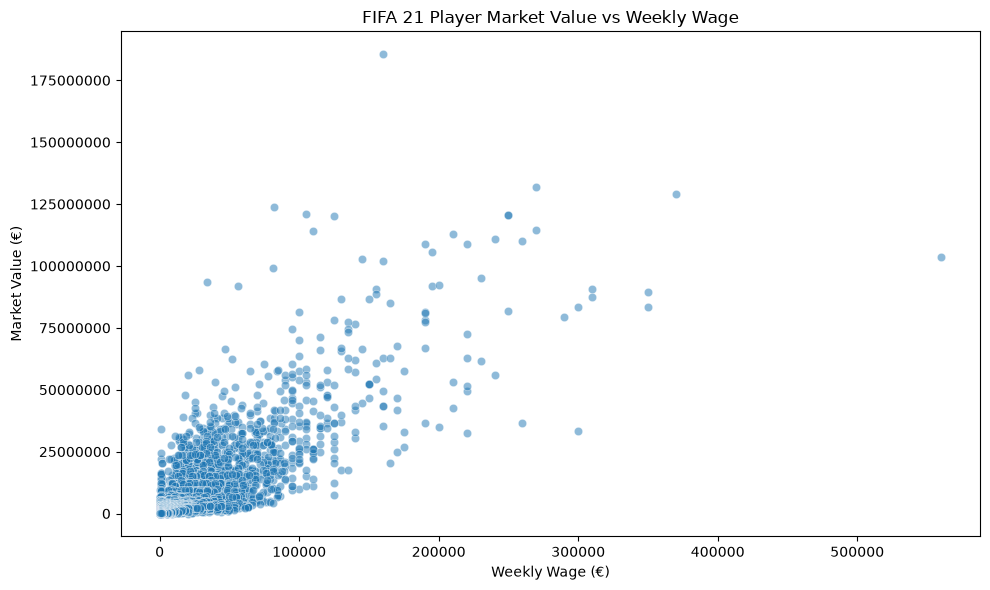

In [83]:
# creating a scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Wage",
    y="Value",
    alpha=0.5
)

plt.title("FIFA 21 Player Market Value vs Weekly Wage")
plt.xlabel("Weekly Wage (€)")
plt.ylabel("Market Value (€)")

plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

In [84]:
# identifying potentially underpaid players

# separate dataset for this analysis
analysis_df = df.dropna(subset=["Value", "Wage"]).copy()

# Remove players with zero or negative values
analysis_df = analysis_df[
    (analysis_df["Value"] > 0) &
    (analysis_df["Wage"] > 0)
]

# Divide players into 10 market-value groups
analysis_df["Value_Band"] = pd.qcut(
    analysis_df["Value"],
    q=10,
    duplicates="drop"
)

# Calculate the median wage in each value group
analysis_df["Band_Median_Wage"] = (
    analysis_df.groupby("Value_Band", observed=True)["Wage"]
    .transform("median")
)

# Compare each player's wage with their group's median
analysis_df["Wage_vs_Band_Median"] = (
    analysis_df["Wage"] / analysis_df["Band_Median_Wage"]
)

# Select high-value players earning below their group's median
candidates = analysis_df[
    (analysis_df["Value"] >= analysis_df["Value"].quantile(0.75)) &
    (analysis_df["Wage_vs_Band_Median"] < 1)
]

# Display the 20 highest-value candidates
candidates = candidates.sort_values(
    by=["Value", "Wage_vs_Band_Median"],
    ascending=[False, True]
)

candidates[
    [
        "Name",
        "Club",
        "Value",
        "Wage",
        "Band_Median_Wage",
        "Wage_vs_Band_Median"
    ]
].head(20)

,Name,Club,Value,Wage,Band_Median_Wage,Wage_vs_Band_Median
276,Cucurella,Getafe CF,58000000.0,28000.0,34000.0,0.823529
108,Grimaldo,SL Benfica,56000000.0,20000.0,34000.0,0.588235
101,A. Onana,Ajax,48000000.0,18000.0,34000.0,0.529412
129,J. Corona,FC Porto,45000000.0,25000.0,34000.0,0.735294
155,Pau López,Roma,42500000.0,25000.0,34000.0,0.735294
125,Pizzi,SL Benfica,40500000.0,25000.0,34000.0,0.735294
118,N. Tagliafico,Ajax,40500000.0,27000.0,34000.0,0.794118
305,Everton,SL Benfica,39000000.0,17000.0,34000.0,0.500000
161,Rafa,SL Benfica,38500000.0,23000.0,34000.0,0.676471
193,Oscar,Shanghai SIPG FC,36500000.0,25000.0,34000.0,0.735294
